正在计算 g=1.5 的情况 (5x5 共 25 张图)，这需要一些时间，请稍候...
计算完成！全局数值范围设定为: [-0.318, 0.318]
正在显示图像...


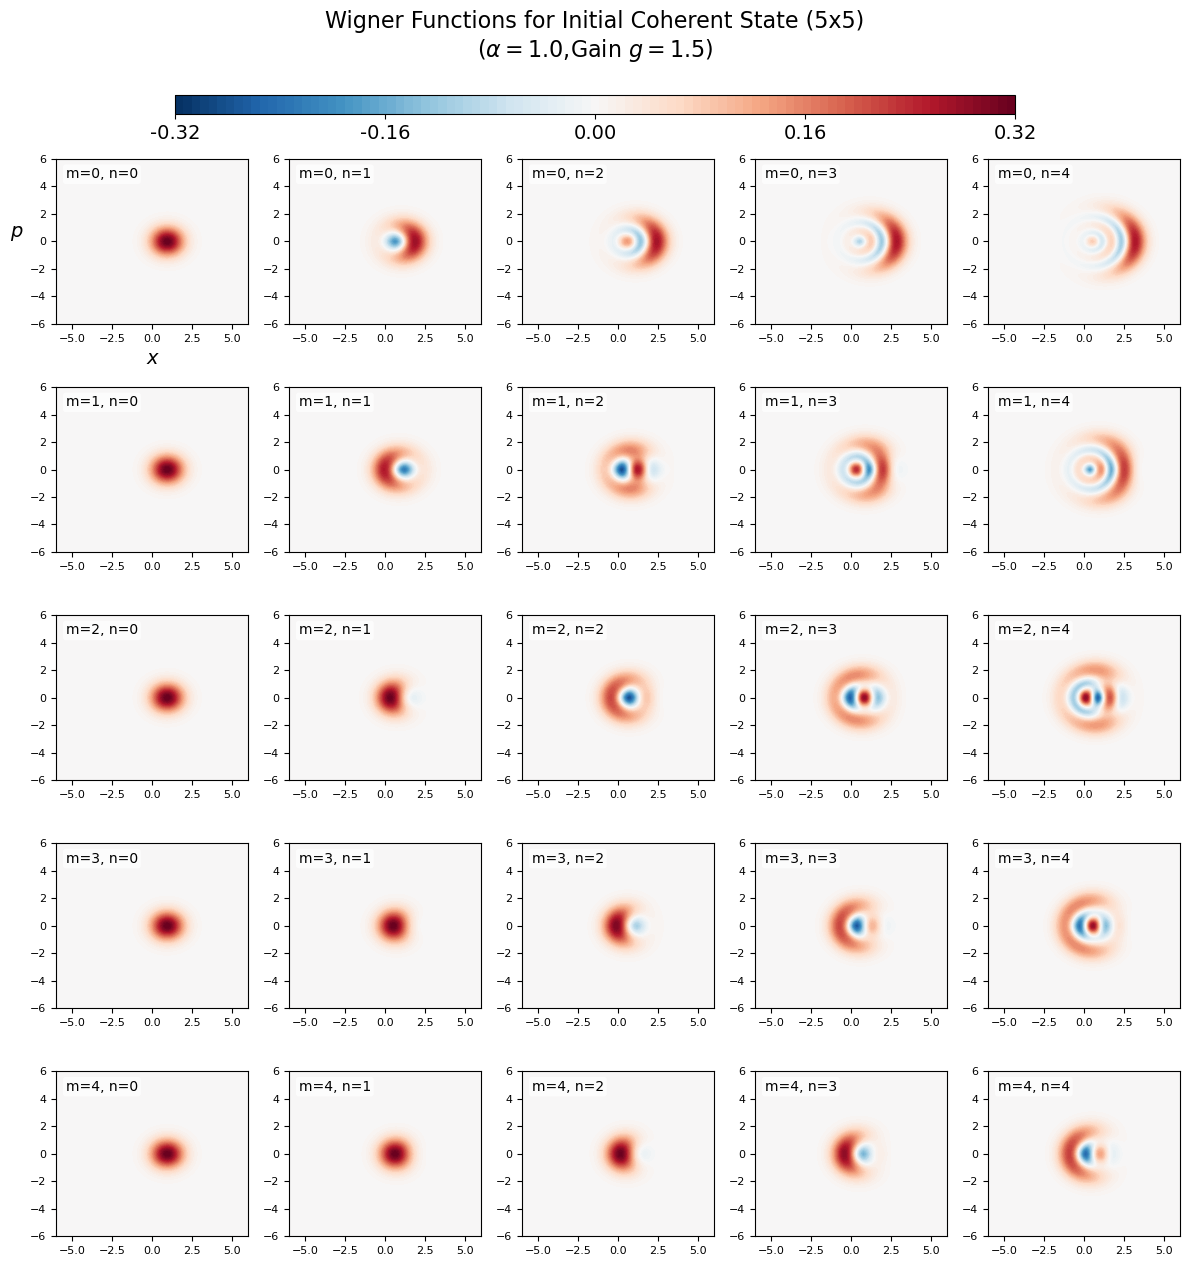

In [1]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt

def plot_wigner_amplifier_5x5_final(g_val, alpha_mag=1.0, alpha_phase=0, N_dim=100):
    """
    绘制相干态经过放大器后的 Wigner 函数 5x5 网格图。
    包含全局顶部精确色条，无箭头，以及精确匹配参考图的浅灰色背景 (#F5F5F5)。
    """
    if g_val < 1.0:
        raise ValueError("物理错误：放大增益 g 的值必须大于或等于 1.0")

    print(f"正在计算 g={g_val} 的情况 (5x5 共 25 张图)，这需要一些时间，请稍候...")

    # ==========================================
    # 1. 物理参数与算符初始化
    # ==========================================
    m_list = [0, 1, 2, 3, 4]
    n_list = [0, 1, 2, 3, 4]
    
    g = g_val
    G = np.sqrt(1 - 1 / (g**2)) 
    
    alpha = alpha_mag * np.exp(1j * alpha_phase) 

    a = qt.destroy(N_dim)
    adag = a.dag()

    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])

    phi_state = qt.coherent(N_dim, alpha)

    xvec = np.linspace(-6, 6, 200)

    # ==========================================
    # 2. 一次性计算并存储所有 Wigner 矩阵 (提升速度)
    # ==========================================
    wigner_matrices = np.zeros((len(m_list), len(n_list), len(xvec), len(xvec)))

    for i, m in enumerate(m_list):
        for j, n in enumerate(n_list):
            psi_out = qt.basis(N_dim, 0) * 0.0

            for k in range(m + 1):
                if n - m + k < 0:
                    continue
                    
                num1 = (-1)**(n - m + k)
                den1 = g**(m - k + 1)
                
                num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
                den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
                
                coef = (num1 / den1) * (num2 / den2)
                term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * phi_state
                psi_out += term_state

            psi = psi_out.unit()
            wigner_matrices[i, j] = qt.wigner(psi, xvec, xvec)

    # 提取全局对称的数值范围
    max_w = np.max(np.abs(wigner_matrices))
    print(f"计算完成！全局数值范围设定为: [{-max_w:.3f}, {max_w:.3f}]")

    # ==========================================
    # 3. 画布设置与绘图 (5x5)
    # ==========================================
    # 调整高度以预留顶部色条空间
    fig, axes = plt.subplots(5, 5, figsize=(12, 13))
    
    levels = np.linspace(-max_w, max_w, 100)

    for i, m in enumerate(m_list):
        for j, n in enumerate(n_list):
            ax = axes[i, j]
            W = wigner_matrices[i, j]

            # 绘制等高线填充图
            cont = ax.contourf(xvec, xvec, W, levels=levels, cmap='RdBu_r')
            
            # ==========================================
            # ★ 核心修改：设置子图背景色为图片中的浅灰色 ★
            # ==========================================
            ax.set_facecolor('#F5F5F5')
            
            ax.set_xlabel('')
            ax.set_ylabel('')
            
            if i == 0 and j == 0:
                ax.set_xlabel('x', fontsize=14, fontstyle='italic')
                ax.set_ylabel('p', fontsize=14, fontstyle='italic', rotation=0, labelpad=10)
            
            ax.text(0.05, 0.95, f"m={m}, n={n}", transform=ax.transAxes, 
                    fontsize=10, verticalalignment='top', horizontalalignment='left',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
            
            ax.tick_params(axis='both', which='major', labelsize=8)

    # 安排子图布局，预留顶部空间给色条和标题 (限制画图区域在 0.88 以下)
    plt.tight_layout(rect=[0, 0.01, 1, 0.88])

    # ==========================================
    # 4. ★ 标准化：绝对定位生成顶部完美色条 ★
    # ==========================================
    cbar_ticks = [-max_w, -max_w/2, 0, max_w/2, max_w]
    
    # [左边距, 下边距, 宽度, 高度(厚度)]
    cbar_ax = fig.add_axes([0.15, 0.90, 0.7, 0.015]) 
    
    cbar = fig.colorbar(mappable=cont, cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    # 刻度保留2位小数
    cbar.ax.set_xticklabels([f"{t:.2f}" for t in cbar_ticks], fontsize=14)

    # ==========================================
    # 5. 渲染与显示
    # ==========================================
    fig.suptitle(f"Wigner Functions for Initial Coherent State (5x5)\n"
                 f"($\\alpha={alpha_mag}$,Gain $g={g_val}$)", 
                 fontsize=16, y=0.98)
    
    print(f"正在显示图像...")
    plt.show()

# =====================================================================
# ★ 运行代码 ★
# =====================================================================
plot_wigner_amplifier_5x5_final(g_val=1.5)

正在计算 g=1.5 的情况 (5x5 共 25 张图)，这需要一些时间，请稍候...
计算完成！全局数值范围设定为: [-0.318, 0.318]
正在显示图像...


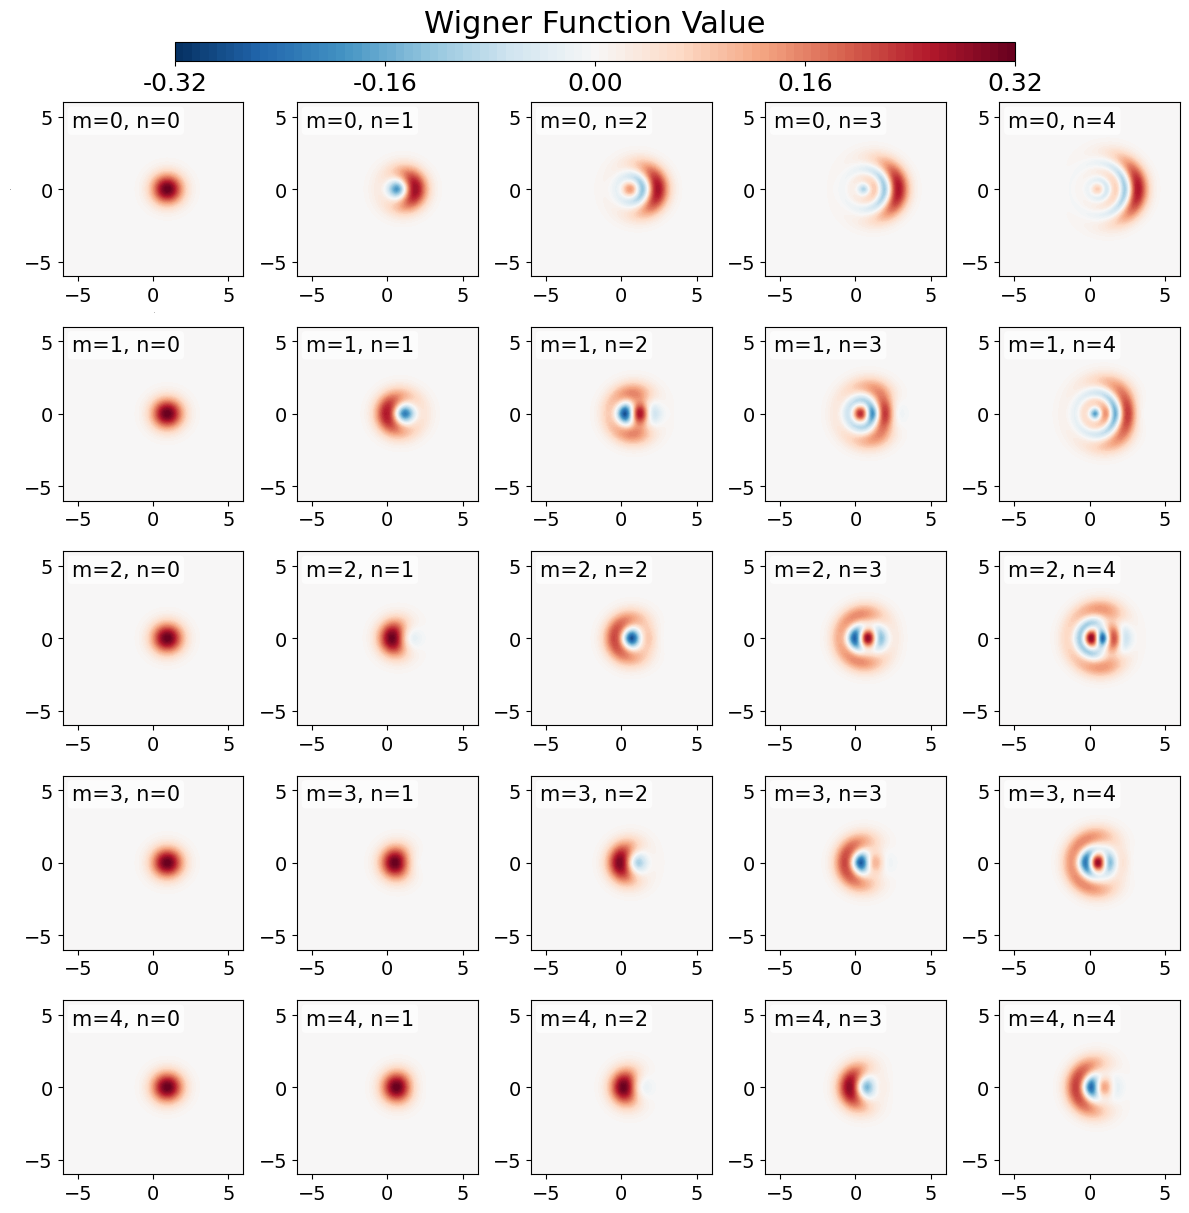

In [1]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt

def plot_wigner_amplifier_5x5_final(g_val, alpha_mag=1.0, alpha_phase=0, N_dim=100):
    """
    绘制相干态经过放大器后的 Wigner 函数 5x5 网格图。
    包含全局顶部精确色条，无箭头，以及精确匹配参考图的浅灰色背景 (#F5F5F5)。
    """
    if g_val < 1.0:
        raise ValueError("物理错误：放大增益 g 的值必须大于或等于 1.0")

    # ==========================================
    # --- 字体与排版参数设置区 (请在这里调整大小) ---
    # ==========================================
    FIG_SIZE = (12, 13)        # 画布整体尺寸 (宽, 高)
    TITLE_SIZE = 18            # 总标题字体大小
    LABEL_SIZE = 1            # 坐标轴标签 (x, p) 字体大小
    TICK_SIZE = 14             # 子图坐标轴刻度数字大小
    TEXT_BOX_SIZE = 15         # 子图内 "m=, n=" 文本框字体大小
    CBAR_TICK_SIZE = 22        # 顶部色条数字字体大小
    CBAR_TICK_SIZE = 18          # 顶部色条数字刻度大小
    # ==========================================

    print(f"正在计算 g={g_val} 的情况 (5x5 共 25 张图)，这需要一些时间，请稍候...")

    # ==========================================
    # 1. 物理参数与算符初始化
    # ==========================================
    m_list = [0, 1, 2, 3, 4]
    n_list = [0, 1, 2, 3, 4]
    
    g = g_val
    G = np.sqrt(1 - 1 / (g**2)) 
    
    alpha = alpha_mag * np.exp(1j * alpha_phase) 

    a = qt.destroy(N_dim)
    adag = a.dag()

    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])

    phi_state = qt.coherent(N_dim, alpha)

    xvec = np.linspace(-6, 6, 200)

    # ==========================================
    # 2. 一次性计算并存储所有 Wigner 矩阵 (提升速度)
    # ==========================================
    wigner_matrices = np.zeros((len(m_list), len(n_list), len(xvec), len(xvec)))

    for i, m in enumerate(m_list):
        for j, n in enumerate(n_list):
            psi_out = qt.basis(N_dim, 0) * 0.0

            for k in range(m + 1):
                if n - m + k < 0:
                    continue
                    
                num1 = (-1)**(n - m + k)
                den1 = g**(m - k + 1)
                
                num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
                den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
                
                coef = (num1 / den1) * (num2 / den2)
                term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * phi_state
                psi_out += term_state

            psi = psi_out.unit()
            wigner_matrices[i, j] = qt.wigner(psi, xvec, xvec)

    # 提取全局对称的数值范围
    max_w = np.max(np.abs(wigner_matrices))
    print(f"计算完成！全局数值范围设定为: [{-max_w:.3f}, {max_w:.3f}]")

    # ==========================================
    # 3. 画布设置与绘图 (5x5)
    # ==========================================
    # 使用自定义的 FIG_SIZE
    fig, axes = plt.subplots(5, 5, figsize=FIG_SIZE)
    
    levels = np.linspace(-max_w, max_w, 100)

    for i, m in enumerate(m_list):
        for j, n in enumerate(n_list):
            ax = axes[i, j]
            W = wigner_matrices[i, j]

            cont = ax.contourf(xvec, xvec, W, levels=levels, cmap='RdBu_r')
            
            ax.set_facecolor('#F5F5F5')
            
            ax.set_xlabel('')
            ax.set_ylabel('')
            
            if i == 0 and j == 0:
                # 应用自定义坐标轴标签大小
                ax.set_xlabel('x', fontsize=LABEL_SIZE, fontstyle='italic')
                ax.set_ylabel('p', fontsize=LABEL_SIZE, fontstyle='italic', rotation=0, labelpad=10)
            
            # 应用自定义文本框字体大小
            ax.text(0.05, 0.95, f"m={m}, n={n}", transform=ax.transAxes, 
                    fontsize=TEXT_BOX_SIZE, verticalalignment='top', horizontalalignment='left',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
            
            # 应用自定义坐标轴刻度大小
            ax.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
            # ★ 在这里加上这两行，强制只显示特定的刻度 ★
            ax.set_yticks([-5, 0, 5])
            ax.set_xticks([-5, 0, 5])  # 建议横坐标也统一改成这样，保持画面对称

    # 安排子图布局
    plt.tight_layout(rect=[0, 0.01, 1, 0.88])

    # ==========================================
    # 4. 标准化：绝对定位生成顶部完美色条
    # ==========================================
    cbar_ticks = [-max_w, -max_w/2, 0, max_w/2, max_w]
    
    cbar_ax = fig.add_axes([0.15, 0.90, 0.7, 0.015]) 
    
    cbar = fig.colorbar(mappable=cont, cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    
    # 应用自定义色条数字字体大小
    cbar.ax.set_xticklabels([f"{t:.2f}" for t in cbar_ticks], fontsize=CBAR_TICK_SIZE)

    # ==========================================
    # 5. 渲染与显示
    # ==========================================
    # 应用自定义总标题大小
    print(f"正在显示图像...")
    fig.suptitle(f"Wigner Function Value", fontsize=22, y=0.94)
    plt.show()

# =====================================================================
# ★ 运行代码 ★
# =====================================================================
plot_wigner_amplifier_5x5_final(g_val=1.5)